# DSAI 3201 — Checkpoint 1 


**Lina Benhamiche 60310676**

**Lercia Mussane 60306713** 


**Decision:** At chocks-on, predict minutes until the first bag reaches the belt; a breach means `wait_min > 25`. Observational predictions do not prove an extra team causes improvement.

**Assessment coverage:** six checkpoint items; no hour-basis search, tree, or vendor model is required.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
print("pandas",pd.__version__,"numpy",np.__version__,"sklearn",sklearn.__version__)
SEED=3201

pandas 3.0.2 numpy 2.4.6 sklearn 1.8.0


## 1. Data integrity and date-defined splits


In [2]:
df=pd.read_csv("hia_arrivals.csv",parse_dates=["flight_date"])
print("Rows",len(df),"Date range",df.flight_date.min().date(),df.flight_date.max().date())
print("Unique flight IDs",df.flight_id.nunique(),"Duplicate IDs",df.flight_id.duplicated().sum())
print("Missing counts:\n",df.isna().sum().to_string())
for col in ["origin_region","belt","dow"]: print(col,sorted(df[col].dropna().unique().tolist()))
blocks={"Fit":df[df.flight_date.between("2025-09-01","2025-11-23")].copy(),"Validation":df[df.flight_date.between("2025-11-24","2025-12-14")].copy(),"Hold-out":df[df.flight_date.between("2025-12-15","2026-01-04")].copy()}
for name,part in blocks.items():print(name,len(part),part.flight_date.min().date(),part.flight_date.max().date())
assert sum(map(len,blocks.values()))==len(df)
assert df.flight_id.is_unique
fit,val=blocks["Fit"],blocks["Validation"]

Rows 5040 Date range 2025-09-01 2026-01-04
Unique flight IDs 5040 Duplicate IDs 0
Missing counts:
 flight_id                0
flight_date              0
sched_hour               0
dow                      0
origin_region            0
wide_body                0
seats                    0
booked_pax               0
belt                     0
crew_on_duty           194
turnaround_plan_min      0
prev_belt_delay_min      0
temp_c                   0
unload_min               0
bags_scanned             0
pax_complaints           0
flow_index               0
wait_min                 0
origin_region ['africa', 'americas', 'asia', 'europe', 'gulf']
belt [1, 2, 3, 4, 5, 6, 7, 8]
dow [0, 1, 2, 3, 4, 5, 6]
Fit 3360 2025-09-01 2025-11-23
Validation 840 2025-11-24 2025-12-14
Hold-out 840 2025-12-15 2026-01-04


## 2. Feature admission and leakage review
A model can only use information genuinely available at chocks-on. The table below illustrates an evidence-based rationale, not just a correlation ranking.

| Column | Decision | Reason |
|---|---|---|
| `flight_id` | Refuse | Identifier; not a generalizable operational predictor |
| `flight_date` | Split only | Defines chronology, not an input to this model |
| `wait_min` | Target only | Outcome is unknown at decision time |
| `unload_min` | Refuse | Actual unloading duration is observed after the decision; future information |
| `bags_scanned` | Refuse | Actual scanning count is known only during/after baggage handling |
| `pax_complaints` | Refuse | Complaints are post-arrival outcomes, not pre-door-open inputs |
| `flow_index` | Refuse pending provenance | Vendor export index lacks verified chocks-on availability; do not admit merely because predictive |
| `sched_hour`, `dow`, `origin_region`, `wide_body`, `booked_pax`, `belt`, `crew_on_duty`, `turnaround_plan_min`, `prev_belt_delay_min`, `temp_c` | Keep | Listed as available at chocks-on in the data dictionary |
| `seats` | Eligible but omitted in this example | Also available, but potentially redundant with booked passengers; simplify and examine collinearity |

`belt` and `dow` are one-hot encoded. For one-hot features, the first sorted category is the reference. Numeric missing crew counts are imputed using fit-block medians only. No hold-out values inform feature decisions.

In [3]:
for col in ["unload_min","bags_scanned","pax_complaints","flow_index"]:
    print(col,"fit correlation with wait_min:",round(fit[[col,"wait_min"]].corr().iloc[0,1],3))
print("seats vs booked_pax fit correlation:",round(fit[["seats","booked_pax"]].corr().iloc[0,1],3))
print("Missing crew_on_duty (fit):",fit.crew_on_duty.isna().sum())

unload_min fit correlation with wait_min: 0.843
bags_scanned fit correlation with wait_min: 0.362
pax_complaints fit correlation with wait_min: 0.025
flow_index fit correlation with wait_min: 0.506
seats vs booked_pax fit correlation: 0.974
Missing crew_on_duty (fit): 130


## 3. Fit-only mean baseline — validation MAE and RMSE


In [4]:
fit_mean=fit["wait_min"].mean()
baseline_predictions=np.repeat(fit_mean,len(val))
baseline_mae=mean_absolute_error(val["wait_min"],baseline_predictions)
baseline_rmse=np.sqrt(mean_squared_error(val["wait_min"],baseline_predictions))
print(f"Fit-block mean: {fit_mean:.3f} min")
print(f"Validation MAE: {baseline_mae:.3f} min")
print(f"Validation RMSE: {baseline_rmse:.3f} min")

Fit-block mean: 17.628 min
Validation MAE: 5.678 min
Validation RMSE: 7.004 min


## 4. Linear regression and residuals by scheduled hour


Validation linear MAE: 4.52 min
Validation linear RMSE: 5.578 min


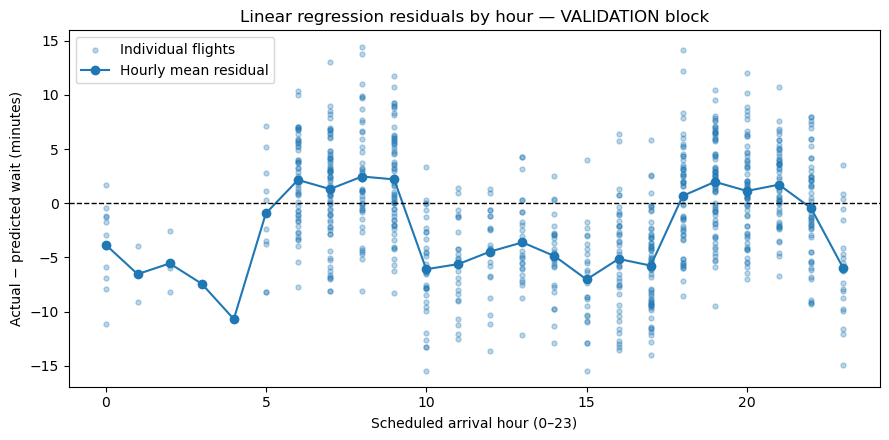

In [5]:
numeric=["sched_hour","wide_body","booked_pax","crew_on_duty","turnaround_plan_min","prev_belt_delay_min","temp_c"]
categorical=["dow","origin_region","belt"]
preprocess=ColumnTransformer([("numeric",SimpleImputer(strategy="median"),numeric),("categorical",Pipeline([("impute",SimpleImputer(strategy="most_frequent")),("encode",OneHotEncoder(handle_unknown="ignore",drop="first"))]),categorical)])
linear=Pipeline([("preprocess",preprocess),("linear",LinearRegression())])
features=numeric+categorical
linear.fit(fit[features],fit["wait_min"])
pred=linear.predict(val[features])
residual=val.wait_min.to_numpy()-pred
print("Validation linear MAE:",round(mean_absolute_error(val.wait_min,pred),3),"min")
print("Validation linear RMSE:",round(np.sqrt(mean_squared_error(val.wait_min,pred)),3),"min")
fig,ax=plt.subplots(figsize=(9,4.5))
ax.scatter(val.sched_hour,residual,alpha=.30,s=13,label="Individual flights")
hourly=pd.DataFrame({"hour":val.sched_hour,"residual":residual}).groupby("hour").residual.mean()
ax.plot(hourly.index,hourly.values,marker="o",label="Hourly mean residual")
ax.axhline(0,color="black",linestyle="--",linewidth=1)
ax.set(xlabel="Scheduled arrival hour (0–23)",ylabel="Actual − predicted wait (minutes)",title="Linear regression residuals by hour — VALIDATION block")
ax.legend();fig.tight_layout();plt.show()

## 5. Fit-block breach rate and misleading majority accuracy
The event is strictly greater than 25 minutes. A model that always predicts the majority class can report strong accuracy while detecting no flights from the minority breach class.

In [6]:
breach=(fit.wait_min>25)
print("Fit breach count:",int(breach.sum()),"of",len(fit))
print("Fit breach rate:",f"{breach.mean():.2%}")
print("Majority-class baseline accuracy on fit:",f"{max(breach.mean(),1-breach.mean()):.2%}")

Fit breach count: 526 of 3360
Fit breach rate: 15.65%
Majority-class baseline accuracy on fit: 84.35%


## 6. Reproducibility, limitations, and AI disclosure
- Used Claude Anthropic to debug and to debug